In [1]:
import numpy as np
import pandas as pd

import glob

import h5py

import cv2

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
import matplotlib.cm as cm

#For image plotting
import skimage.io

import scipy
from scipy import optimize
from scipy.optimize import curve_fit

# Set the property to save figures with text as text, not paths
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

import seaborn as sns
sns.set_context("poster")
sns.set_style("ticks")

In [2]:
######### gabe hacky styling to emulate some of PBoC Phillips lab style conventions, however hacky. tries to make easier for nigel++
## Styling
import matplotlib
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context("poster")
# sns.set_style('ticks')

import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Set the property to save figures with text as text, not paths
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# default good PBoC colors
baseBlendColor=(224/255, 219/255, 209/255,1) # default background for plots
contrastColor=(209/255, 193/255, 171/255,1) # slightly darker tan for contrasts, e.g. in inset boxes
yellowTanHighlightBoxColor='#FEF0C6'
goodGreyGreenArrowColor='#CCD4C9'

### Griffin style invocation

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.path import Path
from matplotlib.patches import BoxStyle
from matplotlib.offsetbox import AnchoredText

def plotting_style(grid=False):
    """
    Sets the style to the publication style. To instantiate, simply call
    plotting_style() at the beginning of your script or notebook to force
    all matplotlib plots to adopt the scheme.

    Parameters
    ----------
    grid: bool
      If True, plots will have a thin, white grid in the background. Default
      is False.

    Returns
    -------
    colors: dict
      Returns a dictionary of the standard PBoC 2e color palette.
    """
    rc = {'axes.facecolor': '#E3DCD0',
#               'axes.spines.top': False,
#               'axes.spines.right': False,
#               'axes.spines.left': False,  # Ensure left spine is present
#               'axes.spines.bottom': False,  # Ensure bottom spine is present
#               'axes.spines.left': False, #{'color': '#E3DCD0', 'linewidth': 1.5},  # Set the spine color to the background color
#               'axes.spines.bottom': False, #{'color': '#E3DCD0', 'linewidth': 1.5},  # Set the spine color to the background color
          #'font.family': '/usr/share/fonts/truetype/LucidaSansOT.otf', #'LucidaSansOT.otf',
          'grid.linestyle': '-',
          'grid.linewidth': 0.5,
          'grid.alpha': 0.75,
          'grid.color': '#ffffff',
          'axes.grid': grid,
          'ytick.direction': 'in',
          'xtick.direction': 'in',
          'xtick.gridOn': grid,
          'ytick.gridOn': grid,
#               'ytick.major.width':8,
#               'xtick.major.width':8,
#               'ytick.major.size': 8,
#               'xtick.major.size': 8,
          'mathtext.fontset': 'stixsans',
          'mathtext.sf': 'sans',
          'legend.frameon': True,
          'legend.facecolor': '#FFEDCE',
          'figure.dpi': 150,
          'xtick.color': 'k',
          'ytick.color': 'k'
         }
    plt.rc('text.latex', preamble=r'\usepackage{sfmath}')
    plt.rc('mathtext', fontset='stixsans', sf='sans')
    sns.set_style('darkgrid', rc=rc)
    return color_palette()

def color_palette():
    """
    Returns a dictionary of the PBOC color palette
    """
    return {'green': '#7AA974', 'light_green': '#BFD598',
              'pale_green': '#DCECCB', 'yellow': '#EAC264',
              'light_yellow': '#F3DAA9', 'pale_yellow': '#FFEDCE',
              'blue': '#738FC1', 'light_blue': '#A9BFE3',
              'pale_blue': '#C9D7EE', 'red': '#D56C55', 'light_red': '#E8B19D',
              'pale_red': '#F1D4C9', 'purple': '#AB85AC',
              'light_purple': '#D4C2D9', 'dark_green':'#7E9D90', 'dark_brown':'#905426'}

def titlebox(
    ax, text, color, bgcolor=None, size=8, boxsize=0.1, pad=0.05, **kwargs
):
    """
    Sets a colored title box above the plot, spanning the entire plot width.

    Parameters
    ----------
    ax : matplotlib axis object
      The axis on which you want to add the titlebox.
    text: str
      The title tect
    bgcolor: str or None
      The background color of the title box. Default is no color (blank).
    size:  int
      Size of the text font
    boxsize: float [0, 1]
      Fraction of the total plot height to be occupied by the box. Default is 10% (0.1).
    pad: float
      The padding space between the title box and the top of the plot.

    """
    boxsize=str(boxsize * 100)  + '%'
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("top", size=boxsize, pad=pad)
    cax.get_xaxis().set_visible(False)
    cax.get_yaxis().set_visible(False)
    cax.spines["top"].set_visible(False)
    cax.spines["right"].set_visible(False)
#     cax.spines["bottom"].set_visible(False)
#     cax.spines["left"].set_visible(False)

#     cax.spines["bottom"].set_visible(True)
#     cax.spines["left"].set_visible(True)
#     cax.spines["left"].set_color("white")
#     cax.spines["bottom"].set_color("white")
#     cax.spines["bottom"].set_color("white")

#     cax.set_ticks_position('both')  # Adding ticks to both top and bottom
#     cax.yaxis.set_tick_params(direction='in', which='both', color='white')  # The bottom will maintain the default of 'out'


    plt.setp(cax.spines.values(), color=color)
    if bgcolor != None:
        cax.set_facecolor(bgcolor)
    else:
        cax.set_facecolor("white")
    at = AnchoredText(text, loc=10, frameon=False, prop=dict(size=size, color=color))
    cax.add_artist(at)


### Now actually call it
plotting_style()

import matplotlib.patheffects as pe
matplotlib.rcParams['axes.autolimit_mode'] = 'data'

# Functions

In [3]:
def read_h5py(path_name, excludes=[], includes=[]):
    # Glob for directory parsing to get all .h5 files in the specified path
    h5files = glob.glob(path_name + '/*.h5')
    for excl in excludes:
        h5files=[file for file in h5files if excl not in file]
    for incl in includes:
        h5files=[file for file in h5files if incl in file]

    print(len(h5files))
        
    #print("HDF5 files found:", h5files)
    
    # Dictionary to store arrays from each file
    all_data = {}
    
    for file in h5files:
        file_data = []  # List to hold datasets for the current file
        
        with h5py.File(file, 'r') as h5file:
            def load_data(name, obj):
                if isinstance(obj, h5py.Dataset):
                    file_data.append(obj[:])  # Append dataset as a NumPy array
            
            # Visit all datasets in the file and load them into file_data
            h5file.visititems(load_data)
        
        #slice by 8 since the date has 8 didgits
        field_name = file.split('.h5')[0].split('tif')[-1][15:] #BRO, 15 is the number of digits in how we save datetime -> 20241114_201131 (formerly we had 8 since we didnt include time)
        #print(file + '\n')
        #print(field_name+ '\n')
            
        # Add this file's data to all_data with the filename as the key
        all_data[field_name] = file_data[0]
        
        
    return all_data

In [4]:
def makeImFromValsList(valuesList, mask_coords, imshape):
    """ valuesList: numTimepoints x numValues, such that valuesList[t,:] is the list of values we populate in the returned image/array
        mask_coords: tuple of length 2; the first entry is 1d array of rowNums and the second entry is 1d array of colNums, of length = numValues (defined in mask)
        imshape: numImgRows x numImgCols.
        
        Returns imgArrayTotal = (numTimepoints x numImgRows x numImgCols) array where things are zero when outside the mask and otherwise populated by the provided valuesList in appropriate positions.
    """
    imgArrayTotal = np.zeros((len(valuesList), imshape[0], imshape[1]))
    for t in range(len(valuesList)):
        imgArrayTotal[t,mask_coords[0], mask_coords[1]]=valuesList[t,:]
    
    return imgArrayTotal

In [5]:
import xml.etree.ElementTree as ET
def grabxml(annotPath):
    tree = ET.parse(annotPath)  # Replace with actual filename
    root = tree.getroot()
    
    # --- Step 1: Extract task info indexed by task ID ---
    task_data = {}
    for task in root.findall(".//task"):
        task_id = task.find("id").text
        task_data[task_id] = {
            "task_start_frame": int(task.find("start_frame").text),
            "task_stop_frame": int(task.find("stop_frame").text),
            "task_source": task.find("source").text
        }
    
    # --- Step 2: Extract ellipse data inside each track ---
    all_ellipses = []
    
    for track in root.findall("track"):
        track_attrs = track.attrib
        task_id = track_attrs.get("task_id")
        
        # Get task info by task_id
        task_info = task_data.get(task_id, {})
    
        for ellipse in track.findall("ellipse"):
            ellipse_attrs = ellipse.attrib
    
            row = {
                **track_attrs,
                **ellipse_attrs,
                **task_info
            }
    
            all_ellipses.append(row)
    
    # --- Step 3: Convert to DataFrame ---
    annotdf = pd.DataFrame(all_ellipses)
    
    # Optional: convert numeric columns
    for col in ['frame', 'cx', 'cy', 'rx', 'ry', 'z_order', 'task_start_frame', 'task_stop_frame']:
        if col in annotdf.columns:
            annotdf[col] = pd.to_numeric(annotdf[col], errors='coerce')

    return annotdf

In [6]:
def findmp4NameFromGname(gname):
    date = gname.split('assay_')[1].split('/')[0]
    rep = gname.split('/')[-1].split('_MMStack')[0].split('A81D_')[1]
    pos = gname.split('/')[-1].split('MMStack_')[1].split('.ome')[0]
    if 'uM_Ncd' in gname:
        mot = gname.split('uM_Ncd')[0].split('_')[-1]
    elif 'uM_NCD' in gname:
        mot = gname.split('uM_NCD')[0].split('_')[-1]
    atp = gname.split('ATP')[0].split('_')[-1]
    
    mp4name = date+'_r'+rep+'_'+pos+'_mot'+mot+'_atp'+atp+'.mp4'
    return mp4name

In [7]:
def cvatCentandRad(gname, annotPath, imshape):
    annotdf = grabxml(annotPath)
    #for motor sweep
    source = findmp4NameFromGname(gname)
    # #for ATP sweep
    # source = findATPSweepmp4NameFromGname(gname)
    
    annotdf_subset = annotdf[annotdf['task_source']==source]
 
    cvatframes = np.array(annotdf_subset['frame']-annotdf_subset['frame'].max() + annotdf_subset['task_stop_frame'])
    firstkeyframe = cvatframes.min()
    
    firstFramesCenters = np.array([[imshape[1]/2,imshape[0]/2]]*firstkeyframe)
    cvatCenters =  np.array([annotdf_subset['cx'], annotdf_subset['cy']]).T
    centers = np.concat((firstFramesCenters, cvatCenters))
    
    firstFramesLengths = np.array([[np.nan,np.nan]]*firstkeyframe)
    cvatAxesLengths = np.array([annotdf_subset['rx'], annotdf_subset['ry']]).T
    axesLengths = np.concat((firstFramesLengths, cvatAxesLengths))
     
    if len(centers) > 300:
        centers = centers[:300]
        axesLengths = axesLengths[:300]
    return centers, axesLengths

In [8]:
def find_contour(mask):
    #Find contours of binary image
    contours, heirarchy = cv2.findContours(mask.astype(np.uint8), 1, 2)
    #iterate through contours (for most connected region)
    max_area = 0
    max_index = None
    for j, contour in enumerate(contours):
        area = cv2.contourArea(contour)
        if area > max_area:
            max_area = area
            max_index = j

    #Find the coordinates of the illumination pattern contour
    cnt = contours[max_index]
    cnt = np.array(cnt)
    cnt = np.squeeze(cnt)
    return cnt

In [9]:
def min_radius(mango_mask, centers):
    mango_skin_coords = find_contour(mango_mask)
    #reshapes stuff and broadcasts to do subtraction
    dists = np.sqrt(np.sum((mango_skin_coords[:, np.newaxis, :] - centers[np.newaxis, :, :])**2, axis=2))
    #find the minimum distance
    min_dist = np.min(dists)
    # #find the time and position corresponding to the minimum distance
    # min_dist_point, min_dist_time = np.where(dists==min_dist)
    # #find the coordinate of the minimimum distance
    # min_dist_coord = mango_skin_coords[min_dist_point]
    return min_dist

In [10]:
def spaceTimeAvg(imgArray, numTimesWindow, spatialBlock, mode='valid', clip=True):
    """ Also try mode='valid' if you want to only compute time points where the window fits """
    # first, take time running average
    window = np.ones(numTimesWindow) / numTimesWindow
    # 0 refers to first axis (assumed to be time, if imgArray = numTimes x height x width)
    timeAvgd= np.apply_along_axis(lambda m: np.convolve(m, window, mode=mode), 0, imgArray)
    
    # next, do space average
    spaceTimeAvgd=np.zeros((timeAvgd.shape[0], timeAvgd.shape[1]//spatialBlock[0], timeAvgd.shape[1]//spatialBlock[0]))
    for t in range(timeAvgd.shape[0]):
        spaceTimeAvgd[t,:,:]=skimage.measure.block_reduce(timeAvgd[t,:,:],block_size=spatialBlock, func=np.mean)
    
    ## optionally, clip to 99th percentile
    if clip:
        percentile=99.99
        for t in range(spaceTimeAvgd.shape[0]):
            cutOff=np.percentile(spaceTimeAvgd[t,:,:].flatten(), percentile)
            spaceTimeAvgd[t,:,:]=np.where(spaceTimeAvgd[t,:,:]>cutOff, np.nan, spaceTimeAvgd[t,:,:])
    
    return spaceTimeAvgd

def justTimeAvg(imgArray, numTimesWindow, mode='valid'):
    """ Also try mode='valid' if you want to only compute time points where the window fits """
    # first, take time running average
    window = np.ones(numTimesWindow) / numTimesWindow
    # 0 refers to first axis (assumed to be time, if imgArray = numTimes x height x width)
    timeAvgd= np.apply_along_axis(lambda m: np.convolve(m, window, mode=mode), 0, imgArray)
      
    return timeAvgd

In [11]:
def perform_downsamp(arr, timewin, pixelwin, mode=np.nanmean):
    """
    executes the downsampling function safely for a given array and returns a time array
    
    Inputs:
    -------
    arr (np.array): 3d image array of shape
    timewin (integer): number of timesteps to downsample over
    pixelwin (integer): number of pixels to downsample over
    mode (function): method of averaging (i.e. np.nanmean or np.nanmedian)
    
    Returns:
    --------
    times (np.array): 1D array of the frame number corresponding to downsampled images
    arr_downsamped (3d np.array): image array of downsampled data
    """
    
    #Establish time array
    n=arr.shape[0]; #the number of timepoints for this array
    times=1/2*(np.arange(0, n-(timewin-1))+np.arange((timewin-1), n)) 
    
    ###execute the down space timesampling###
    #if pixelwin is not a multiple of the array shape, crop the edge pixels
    if pixelwin != 0:
        offset = arr.shape[-1]%pixelwin
    else:
        offset=0
        
    if offset%2==0:
        if offset==0:
            #dont do anyting
            arr_cropped = arr
        else:
            # trim each side of array evenly
            offset=int(offset/2)
            arr_cropped = arr[:, offset:-offset, offset:-offset]
    else:
        #trim unevenly, we arbitrarily chose
        offset=math.ceil(offset/2)
        arr_cropped = arr[:, (offset-1):-offset, (offset-1):-offset]
        
    #do the downsampling
    arr_downsamped = spaceTimeAvg(arr_cropped, timewin, (pixelwin, pixelwin))
    
    return times, arr_downsamped

# Processing

In [12]:
# Place where the metadata file is found
metaDataFile='../../data/aster/20241114_footageComments_gnames.csv'
metaDF = pd.read_csv(metaDataFile)

# Find data marked as good (in focus and forms an aster)
goodSubset=metaDF[metaDF['Note'].apply(lambda x: 'GOOD' in x)]#[np.isin(metaDF['Note'], "GOOD")]
# make a list of paths to the good data sets
gnameList=list('../../data/aster/'+goodSubset['child']+'/'+goodSubset['FILE']+'/'+goodSubset['Position'])
# save the path to a good example aster which will be the main aster featured in the paper
gname_pc = '../../data/aster/Ncd_Aster_assay_12-11-2023/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif'
#save the index in gnameList that is the path of the example aster
pcidx = np.where(np.array(gnameList)==gname_pc)[0][0]

# cvat annotations - save the path to the data identifying radii and aster centers
annotPath = '../../data/aster/2023-12_NCD_Aster_centerInfo/annotations.xml'

In [13]:
def processGname(gname):
    # define the path that contains the saved h5 datasets (which 
    # are the outputs of data processing) from the dataset path name
    h5spath = gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
    h5dic = read_h5py(h5spath)

    # read into image arrays
    ATP_conc_ims = makeImFromValsList(h5dic['ATP'], h5dic['mask_coords'], h5dic['imshape'])
    mot_conc_ims = makeImFromValsList(h5dic['mot'], h5dic['mask_coords'], h5dic['imshape'])
    mango_mask = makeImFromValsList(np.ones((len(h5dic['mot']), len(h5dic['mask_coords'][0]))), h5dic['mask_coords'], h5dic['imshape'])[0].astype('int')

    #find center information and crop accordingly
    centers, axesLengths = cvatCentandRad(gname, annotPath, ATP_conc_ims[0].shape)
    min_dist = min_radius(mango_mask, centers)
    side_length = int(min_dist/np.sqrt(2))

    #apply the same crop that is seen in figures/movies
    ATPmovieims = []
    motmovieims = []
    
    for i in range(len(ATP_conc_ims)):
        inscribe_crop = np.s_[round(centers[i,1])-side_length:round(centers[i, 1])+side_length,
                         round(centers[i,0])-side_length:round(centers[i,0])+side_length]
        ATPmovieims.append(ATP_conc_ims[i][inscribe_crop])
        motmovieims.append(mot_conc_ims[i][inscribe_crop])
    
    ATPmovieims=np.array(ATPmovieims)
    motmovieims=np.array(motmovieims)

    #downsample ATP
    timesATP, ds_sptm_ATP = perform_downsamp(ATPmovieims, timewin=2, pixelwin=6)
    timesATP_sec=timesATP*20
    
    #define the time  of each frame
    times_sec = np.arange(len(motmovieims))*20 #exp_params['interval']
    times_min = times_sec/60

    return h5dic, ATPmovieims, motmovieims, timesATP_sec, ds_sptm_ATP, times_sec

In [14]:
h5dic, ATPmovieims, motmovieims, timesATP_sec, ds_sptm_ATP, times_sec = processGname(gname_pc)

18


In [16]:
h5spath_pc = gname_pc.split('data')[0]+'analyzed_data'+gname_pc.split('data')[1]+'/'
h5dic_pc = read_h5py(h5spath_pc)

18


/tmp/ipykernel_3740864/2012626240.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


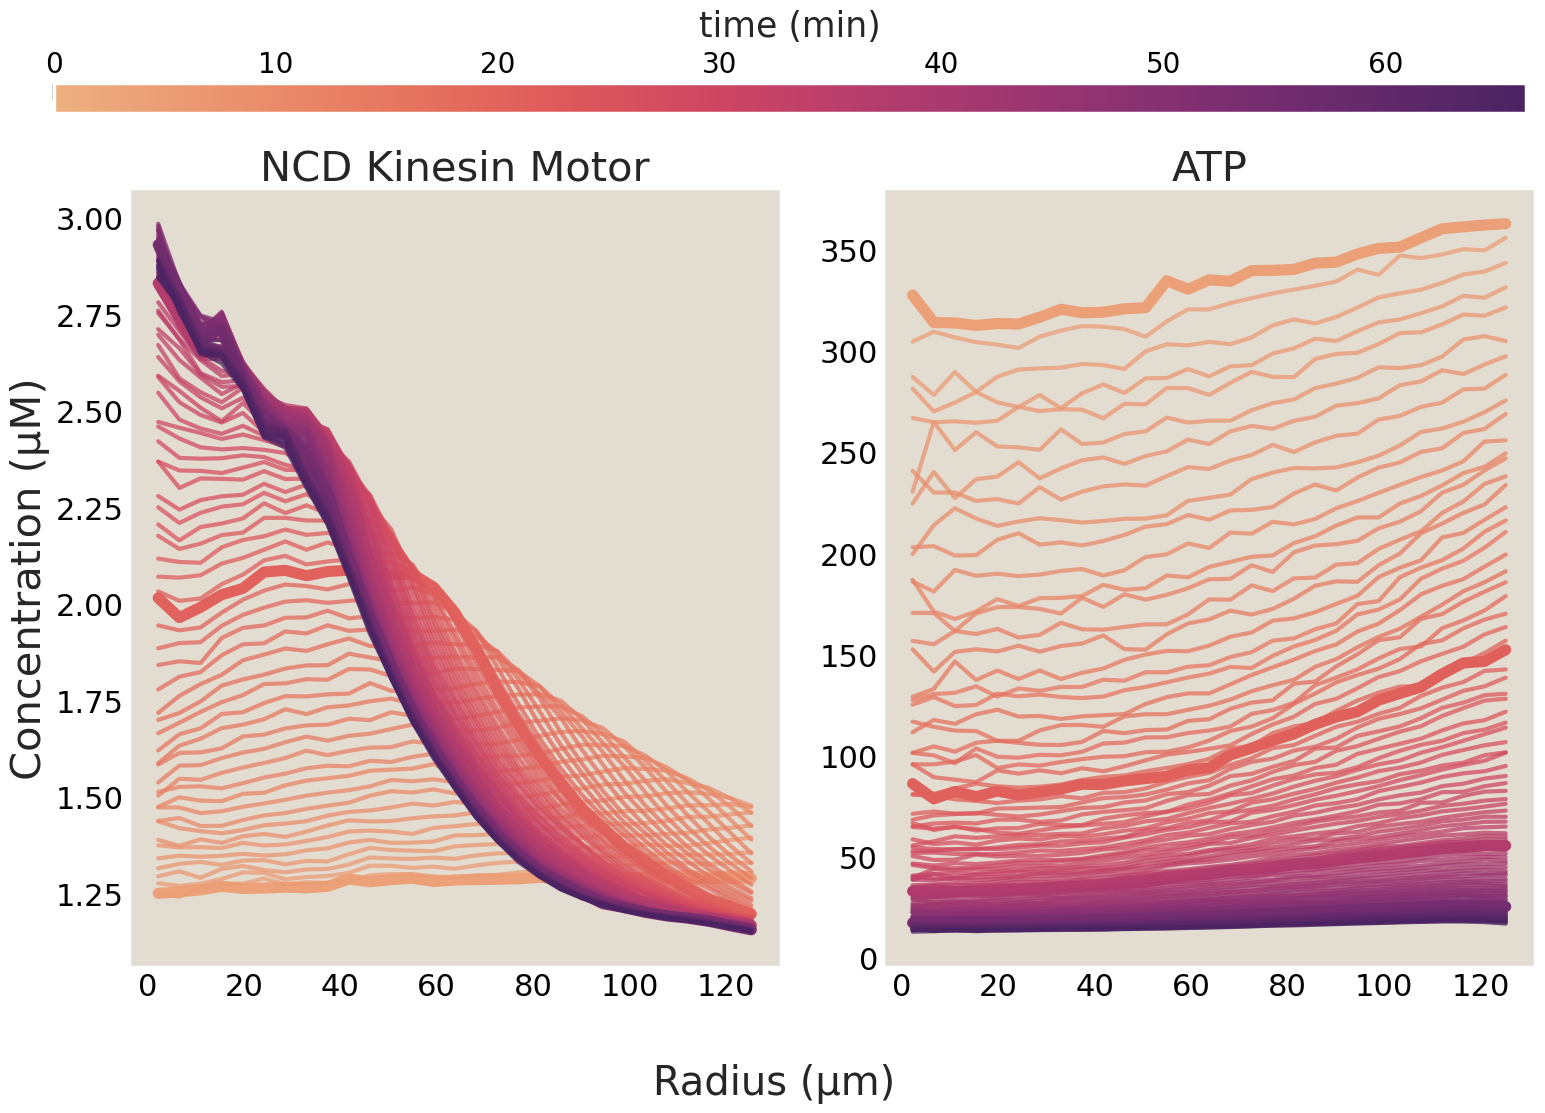

In [18]:
motcrosslinkToIndiv=2
umperpx = 0.59

global_time=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=min([h5dic_pc['timesMot'].min(), h5dic_pc['timesATP'].min()]), vmax=max([h5dic_pc['timesMot'].max(), h5dic_pc['timesATP'].max()]))(time))

fig, ax = plt.subplots(1, 2, figsize=(16,10))
for t, time in enumerate(h5dic_pc['timesMot'][12::2]):
    if np.isin(t*2+12, [12, 62, 112, 162]):
        ax[0].plot(h5dic_pc['all_rMotbins'][t*2+12]*umperpx, # report in individual motor rather than crosslinked pairs
                 h5dic_pc['all_rMotavgs'][t*2+12]*motcrosslinkToIndiv, 
                 alpha=1,
                 lw=8,
                 color=global_time(time))
    else:
        ax[0].plot(h5dic_pc['all_rMotbins'][t*2+12]*umperpx,
                 h5dic_pc['all_rMotavgs'][t*2+12]*motcrosslinkToIndiv, 
                 alpha=0.75,
                 color=global_time(time))


for t, time in enumerate(h5dic_pc['timesATP'][12::2]):
    if np.isin(t*2+12, [12, 62, 112, 162]):
        ax[1].plot(h5dic_pc['all_rATPbins'][t*2+12]*6*umperpx, #since downsampled by 6
                               h5dic_pc['all_rATPavgs'][t*2+12], 
                               alpha=1, 
                               lw=8,
                               color=global_time(time))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
    else:
        ax[1].plot(h5dic_pc['all_rATPbins'][t*2+12]*6*umperpx, #since downsampled by 6
                               h5dic_pc['all_rATPavgs'][t*2+12], 
                               alpha=0.75, 
                               color=global_time(time))

ax[0].set_ylabel('Concentration (µM)', fontsize=30)
fig.supxlabel('Radius (µm)')
ax[1].set_xlim(ax[0].set_xlim())

ax[0].set_title('NCD Kinesin Motor', fontsize=30)
ax[1].set_title('ATP', fontsize=30)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)
#fig.subplots_adjust(right=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(h5dic_pc['timesMot'])/60, 
                                                                 vmax=max(h5dic_pc['timesMot'])/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)




fig.tight_layout()

#plt.savefig(h5spath_pc+'20250629_MotorATPTraces_postBleachCvat_12-11-2023_r1_Pos2.pdf', bbox_inches='tight', transparent=True)
#plt.savefig('20250629_MotorATPTraces_postBleachCvat_12-11-2023_r1_Pos2.pdf', bbox_inches='tight')


# Fit motor profile

In [20]:
def sigmoid(arr, a, b, c, d):
    return a/(1+np.exp((arr - b)/c)) + d
def fitSigmoid(x, y, p0):
    param,_ = curve_fit(sigmoid, x, y, p0)
    return param

def quadratic(arr, a, b, c):
    return a*arr**2 + b*arr + c
def fitQuadratic(x, y, p0):
    param,_ = curve_fit(quadratic, x, y, p0)
    return param

def linear(arr, a, b):
    return a*arr + b
def fitLinear(x, y, p0):
    param,_ = curve_fit(linear, x, y, p0)
    return param
    
def exponential(arr, a, b, c):
    return a*np.exp(-arr/b)+c
def fitExponential(x, y, p0):
    param,_ = curve_fit(exponential, x, y, p0)
    return param

def gaussian(arr, a, b, c, d):
    return a*np.exp(-((arr-b)/c)**2)+d
def fitGaussian(x, y, p0):
    param,_ = curve_fit(exponential, x, y, p0)
    return param

In [21]:
all_rMotbins_um=h5dic_pc['all_rMotbins']*umperpx
all_rMotavgs_mono=h5dic_pc['all_rMotavgs']*motcrosslinkToIndiv
timesMot=h5dic_pc['timesMot']

# explore what characteristic parameter functions should look like

In [24]:
Motmax = np.max(all_rMotavgs_mono, axis=1)
Motmaxloc = [np.where(all_rMotavgs_mono[i] == Motmax[i])[0] for i in range(len(Motmax))]
Motmaxloc = np.concatenate(Motmaxloc)
#added this line - before it was giving the INDEX of the max mt peak rather than position
Motmaxlocum = all_rMotbins_um[0][Motmaxloc]


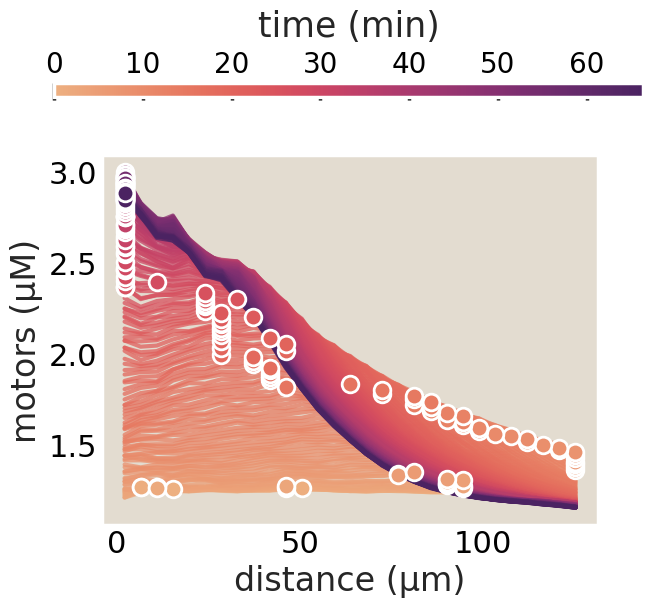

In [55]:
fig, ax = plt.subplots()
for time in range(all_rMotavgs_mono.shape[0]):
    plt.plot(all_rMotbins_um[time,:], all_rMotavgs_mono[time,:], alpha=0.75, color=global_time(timesMot[time]))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
    plt.scatter(Motmaxlocum[time], Motmax[time], color=global_time(timesMot[time]), edgecolors='w', zorder=200)#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
    
plt.ylabel('motors (µM)')
plt.xlabel('distance (µm)')

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(timesMot)/60, 
                                                                 vmax=max(timesMot)/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)

Text(0.5, 0, 'time (s)')

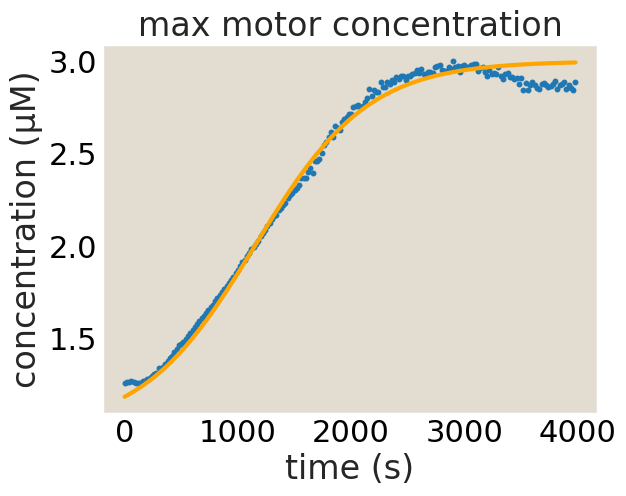

In [35]:
#Motmaxfit = fitQuadratic(timesMot, Motmax, [-15, 500, 15])
#print(Motmaxfit)
plt.scatter(timesMot, Motmax, s=5)
#plt.scatter(timesMot[24:], Motmax[24:], s=5)
# plt.plot(timesMot, sigmoid(timesMot, -1, 1150, 500, 1.5)) #for dimers but not when you mult by 2 for monomers
plt.plot(timesMot, sigmoid(timesMot, -2, 1150, 500, 3), color='orange')
plt.title('max motor concentration')
plt.ylabel('concentration (µM)')
plt.xlabel('time (s)')

Text(0.5, 0, 'time (s)')

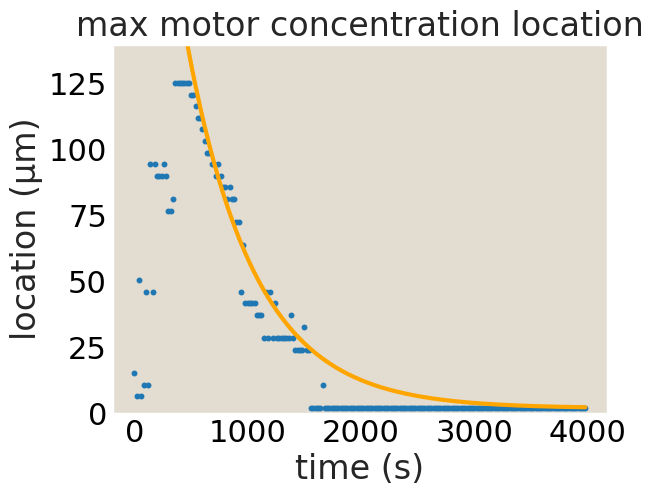

In [38]:
plt.plot(timesMot, exponential(timesMot, 300, 600, 2), color='orange')
plt.scatter(timesMot, Motmaxlocum, s=5)
#plt.scatter(timesMot[24:], Motmaxlocum[24:], s=5)
plt.ylim(0,140)
plt.title('max motor concentration location')
plt.ylabel('location (µm)')
plt.xlabel('time (s)')

Text(0.5, 0, 'time (s)')

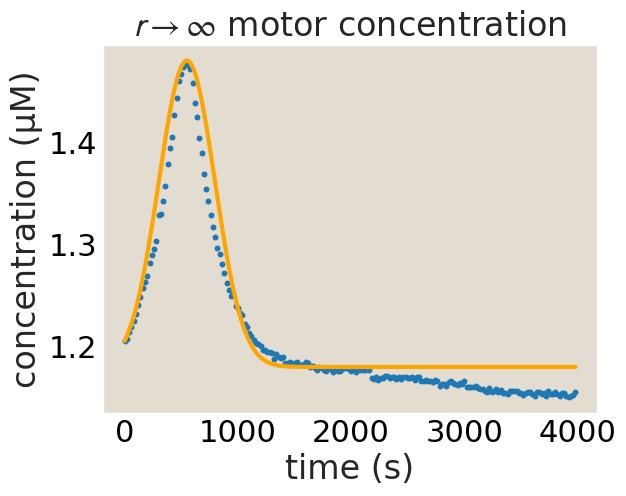

In [48]:
# Motx0fit = fitSigmoid(timesMot,all_rMotavgs[:,0], [15, 1000, 1000, 1])
# print(Motx0fit)
# plt.plot(timesMot, sigmoid(timesMot, *Motx0fit))
plt.plot(timesMot, gaussian(timesMot, 0.3, 550, 350, 1.18), color='orange')
#plt.plot(timesMot, gaussian(timesMot, 0.15, 550, 350, 0.59), color='orange')#for dimers
plt.scatter(timesMot, all_rMotavgs_mono[:,-1], s=5)
plt.title(rf'$r\rightarrow\infty$ motor concentration')
plt.ylabel('concentration (µM)')
plt.xlabel('time (s)')

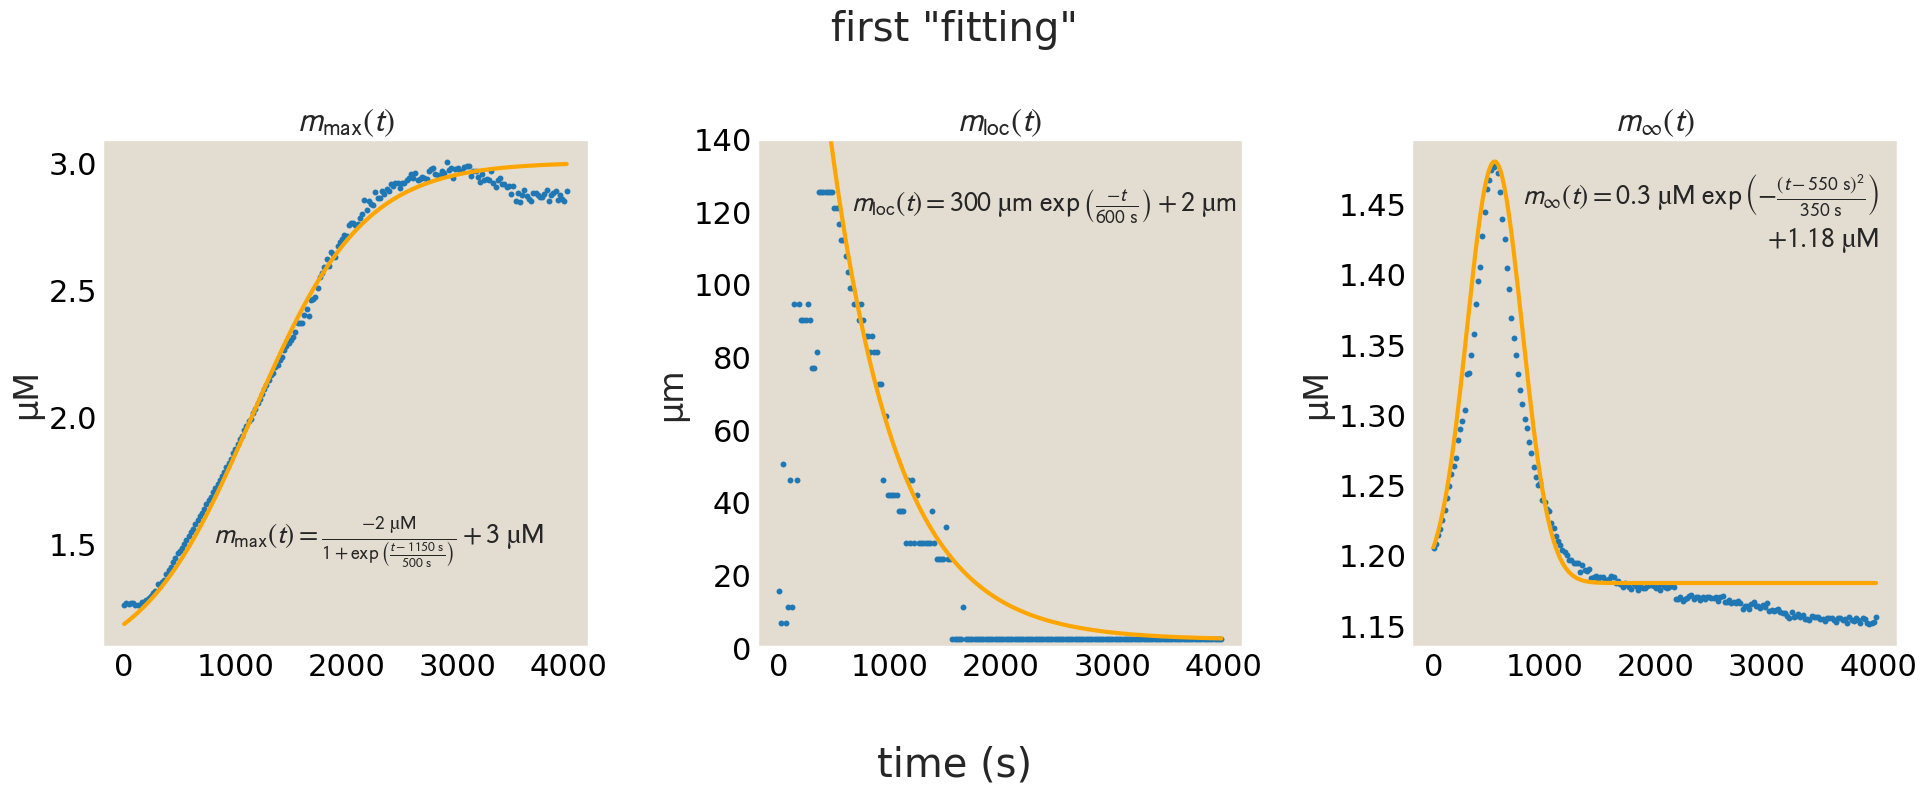

In [195]:
fig, ax = plt.subplots(1,3, figsize=(20,8))

ax[0].scatter(timesMot, Motmax, s=5)
ax[0].plot(timesMot, sigmoid(timesMot, -2, 1150, 500, 3), color='orange')
#ax[0].set_title('max motor concentration')
ax[0].text(800, 1.5, r'$m_\text{max}(t)=\frac{-2\text{ µM}}{1+\exp\left(\frac{t-1150\text{ s}}{500 \text{ s}}\right)}+3\text{ µM}$',fontsize=20)
ax[0].set_title(rf'$m_\text{{max}}(t)$')
ax[0].set_ylabel('µM')

ax[1].plot(timesMot, exponential(timesMot, 300, 600, 2), color='orange')
ax[1].scatter(timesMot, Motmaxlocum, s=5)
ax[1].text(650, 120, r'$m_\text{loc}(t)=300\text{ µm }\exp\left(\frac{-t}{600\text{ s}}\right)+2\text{ µm}$',fontsize=20)
ax[1].set_ylim(0,140)
#ax[1].set_title('max motor concentration location')
ax[1].set_title(rf'$m_\text{{loc}}(t)$')
ax[1].set_ylabel('µm')

ax[2].plot(timesMot, gaussian(timesMot, 0.3, 550, 350, 1.18), color='orange')
ax[2].scatter(timesMot, all_rMotavgs_mono[:,-1], s=5)
#ax[2].set_title(rf'$r\rightarrow\infty$ motor concentration')
ax[2].text(800, 1.45, r'$m_\infty(t)=0.3\text{ µM }\exp\left(-\frac{(t-550\text{ s})^2}{350\text{ s}}\right)$',fontsize=20)
ax[2].text(3000, 1.42, r'$+1.18\text{ µM}$',fontsize=20)
ax[2].set_title(rf'$m_\infty(t)$')
ax[2].set_ylabel('µM')

fig.supxlabel('time (s)')
fig.suptitle('first "fitting"')
plt.tight_layout()
#plt.savefig('../../analyzed_data/aster/20260401_R2_norecycling_647MT_unlabelledNcDmotors/tubMotBound_20260516.pdf', bbox_inches='tight')#, transparent=True)

In [88]:
sigParams=[]
for t in np.arange(all_rMotbins_um.shape[0]):
    sigParams.append(fitSigmoid(all_rMotbins_um[t], all_rMotavgs_mono[t], [sigmoid(timesMot[t], -2, 1150, 500, 3), 
                                                           exponential(timesMot[t], 300, 600, 2), 
                                                           1, 
                                                           gaussian(timesMot[t], 0.3, 550, 350, 1.18)]))
sigParams=np.array(sigParams)

/tmp/ipykernel_3740864/2526617839.py:4: OptimizeWarning: Covariance of the parameters could not be estimated
  param,_ = curve_fit(sigmoid, x, y, p0)
/tmp/ipykernel_3740864/2526617839.py:2: RuntimeWarning: overflow encountered in exp
  return a/(1+np.exp((arr - b)/c)) + d


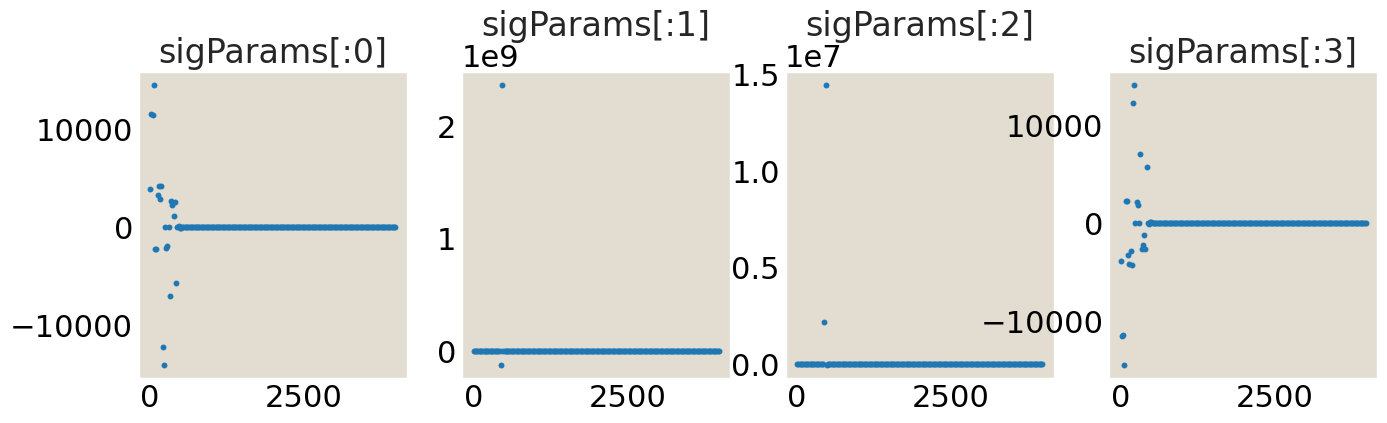

In [89]:
fig, ax = plt.subplots(1,4, figsize=(16,4))
for i in range(4):
    ax[i].scatter(timesMot[:], sigParams[:,i], s=5)
    ax[i].set_title(f'sigParams[:{i}]')

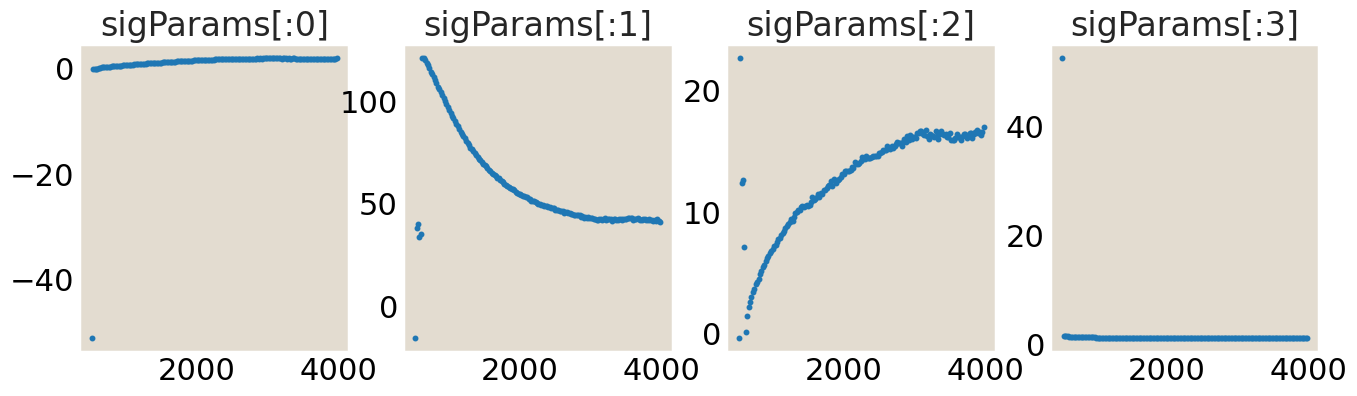

In [90]:
fig, ax = plt.subplots(1,4, figsize=(16,4))
for i in range(4):
    ax[i].scatter(timesMot[26:], sigParams[26:,i], s=5)
    ax[i].set_title(f'sigParams[:{i}]')

(-0.1, 2.0)

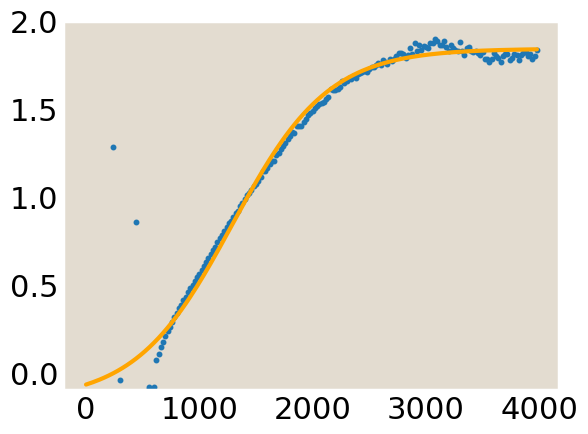

In [98]:
plt.scatter(timesMot, sigParams[:,0], s=5)
#plt.plot(timesMot, sigmoid(timesMot, -1, 1290, 425, 0.92), color='orange')
plt.plot(timesMot, sigmoid(timesMot, -2, 1290, 425, 1.84), color='orange')
plt.ylim(-0.1, 2)


(30.0, 130.0)

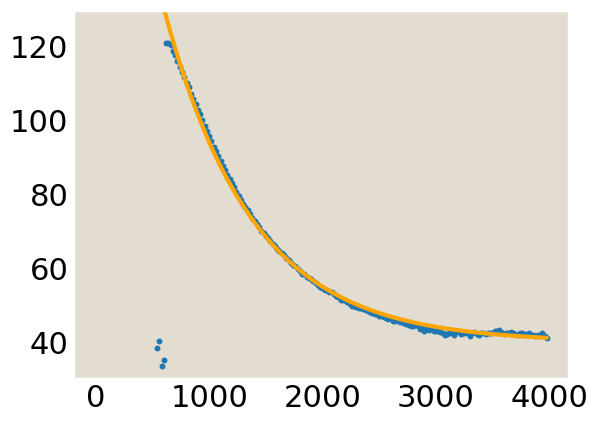

In [99]:
plt.scatter(timesMot, sigParams[:,1], s=5)
plt.plot(timesMot, exponential(timesMot, 195, 780, 40), color='orange')
plt.ylim(30, 130)

(-1.0, 18.0)

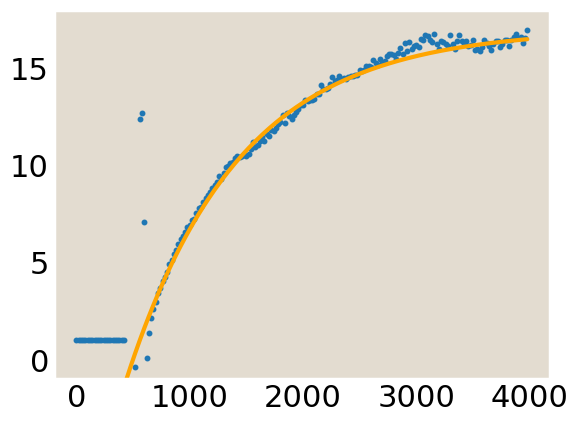

In [100]:
plt.scatter(timesMot, sigParams[:,2], s=5)
plt.plot(timesMot, exponential(timesMot, -28, 1000, 17), color='orange')
#plt.plot(timesMot, sigmoid(timesMot, -15, 1000, 600, 16), color='orange')
plt.ylim(-1, 18)

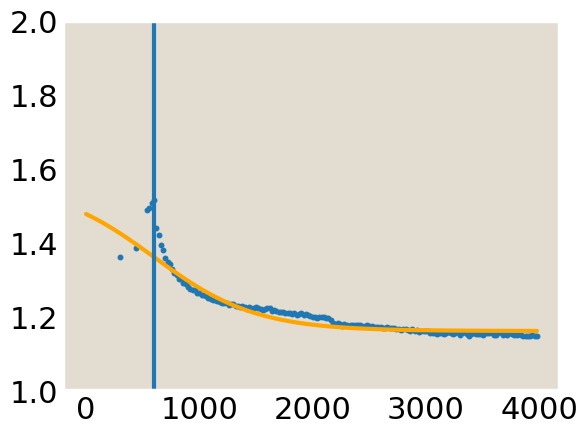

In [107]:
plt.scatter(timesMot, sigParams[:,3], s=5)
#for dimers
# plt.plot(timesMot, exponential(timesMot, 0.35, 550, 0.58), color='orange')
# plt.plot(timesMot, gaussian(timesMot, 0.13, 200, 900, 0.58), color='r')
# plt.plot(timesMot, sigmoid(timesMot, 0.2, 600, 450, 0.58), color='green')

# plt.plot(timesMot, exponential(timesMot, 0.7, 550, 1.16), color='orange')
# plt.plot(timesMot, gaussian(timesMot, 0.26, 200, 900, 1.16), color='r')
plt.plot(timesMot, sigmoid(timesMot, 0.4, 600, 450, 1.16), color='orange')

plt.ylim(1, 2)
plt.axvline(timesMot[30])

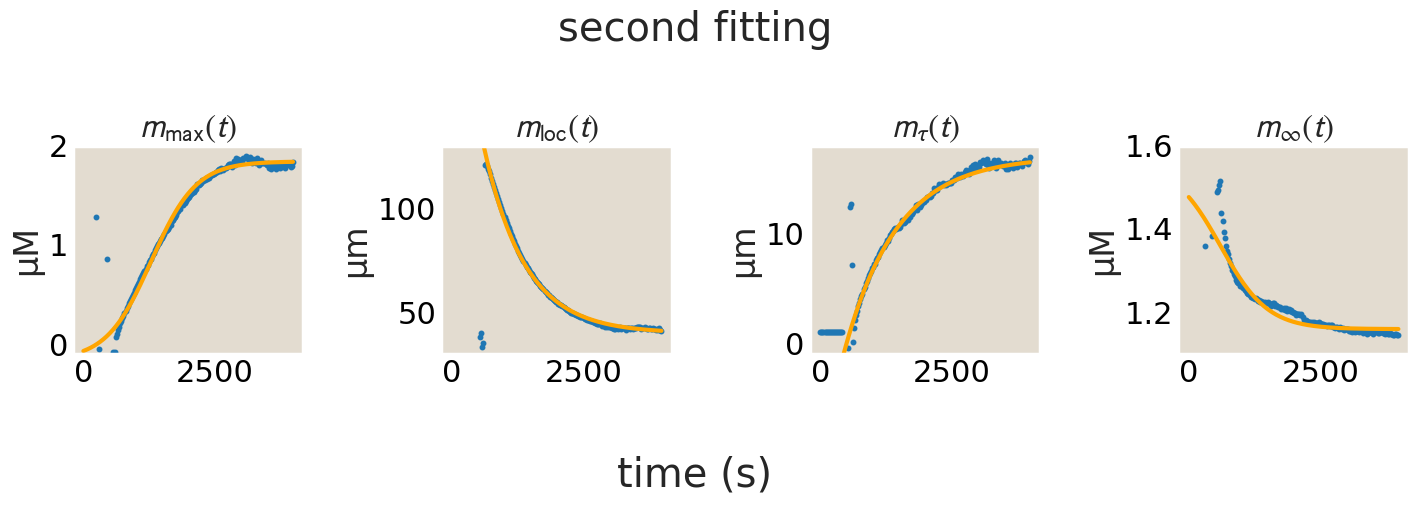

In [125]:
fig, ax = plt.subplots(1,4, figsize=(15,5))

ax[0].scatter(timesMot, sigParams[:,0], s=5)
ax[0].plot(timesMot, sigmoid(timesMot, -2, 1290, 425, 1.84), color='orange')
#ax[0].set_title('max motor concentration')
ax[0].set_title(rf'$m_\text{{max}}(t)$')
ax[0].set_ylabel('µM')
ax[0].set_ylim(-0.1, 2)

ax[1].plot(timesMot, exponential(timesMot, 195, 780, 40), color='orange')
ax[1].scatter(timesMot, sigParams[:,1], s=5)
ax[1].set_ylim(0,140)
#ax[1].set_title('max motor concentration location')
ax[1].set_title(rf'$m_\text{{loc}}(t)$')
ax[1].set_ylabel('µm')
ax[1].set_ylim(30, 130)

ax[2].plot(timesMot, exponential(timesMot, -28, 1000, 17), color='orange')
ax[2].scatter(timesMot, sigParams[:,2], s=5)
#ax[2].set_title(rf'$r\rightarrow\infty$ motor concentration')
ax[2].set_title(rf'$m_\tau(t)$')
ax[2].set_ylabel('µm')
ax[2].set_ylim(-1, 18)

ax[3].plot(timesMot, sigmoid(timesMot, 0.4, 600, 450, 1.16), color='orange')
ax[3].scatter(timesMot, sigParams[:,3], s=5)
ax[3].set_title(rf'$m_\infty(t)$')
ax[3].set_ylabel('µM')
ax[3].set_ylim(1.1, 1.6)

fig.supxlabel('time (s)')
fig.suptitle('second fitting')
plt.tight_layout()

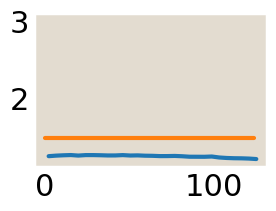

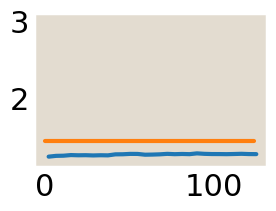

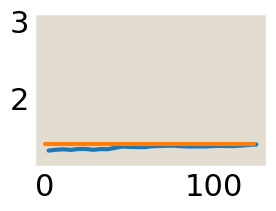

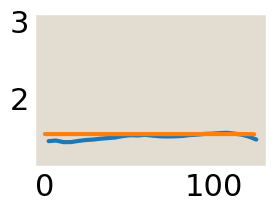

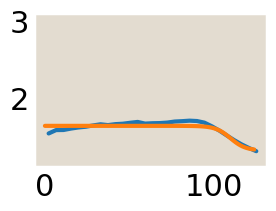

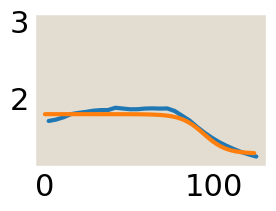

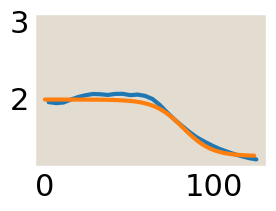

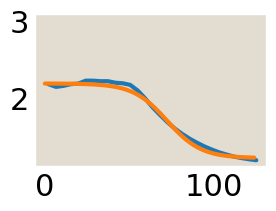

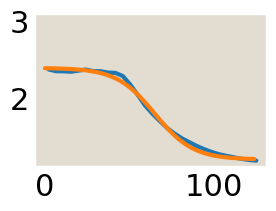

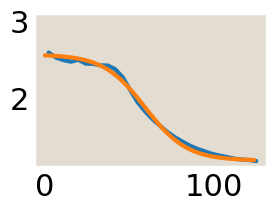

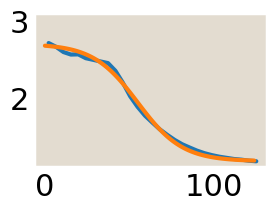

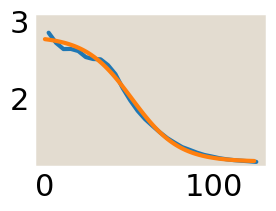

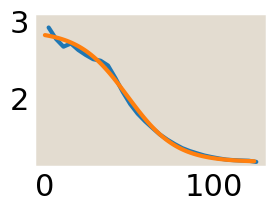

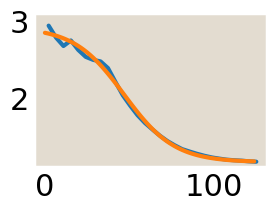

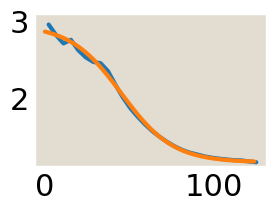

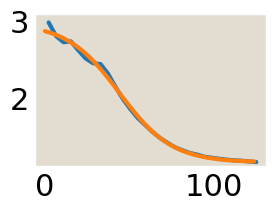

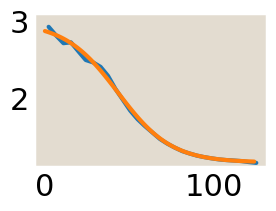

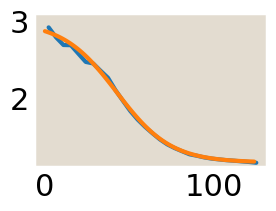

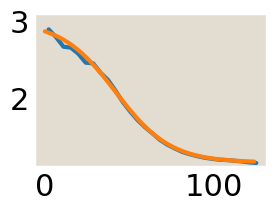

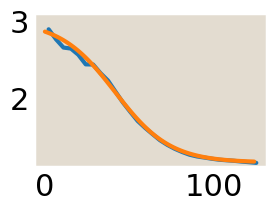

In [129]:
for i in np.arange(0, len(all_rMotbins_um), 10):#len(all_rMTavgs)):
    fig, ax = plt.subplots(figsize=(3,2))
    ax.plot(all_rMotbins_um[i], all_rMotavgs_mono[i])

    #a=sigmoid(timesMot, -1, 1290, 425, 0.92) #for dimer
    a=sigmoid(timesMot, -2, 1290, 425, 1.84)
    b=exponential(timesMot, 195, 780, 40)
    c = exponential(timesMot, -28, 1000, 17)
    #d = sigmoid(timesMot, 0.2, 600, 450, 0.58) #for dimer
    d=sigmoid(timesMot, 0.4, 600, 450, 1.16)
    fitcurveplot = sigmoid(np.arange(int(all_rMotbins_um.max())), a[i], b[i], c[i], d[i])
    ax.plot(np.arange(int(all_rMotbins_um.max())), fitcurveplot)
    #plt.scatter(all_rMTbins[i][MTmaxloc[i]], MTmax[i], c='k', s=10)
    #ax.set_title(np.sum((all_rMTavgs[i] - fitcurveplot)**2))
    ax.set_ylim(1.1, 3.1)

In [132]:
len(all_rMotbins_um)

200

In [135]:
i

np.int64(20)

Text(0.5, 0.01, 'distance (µm)')

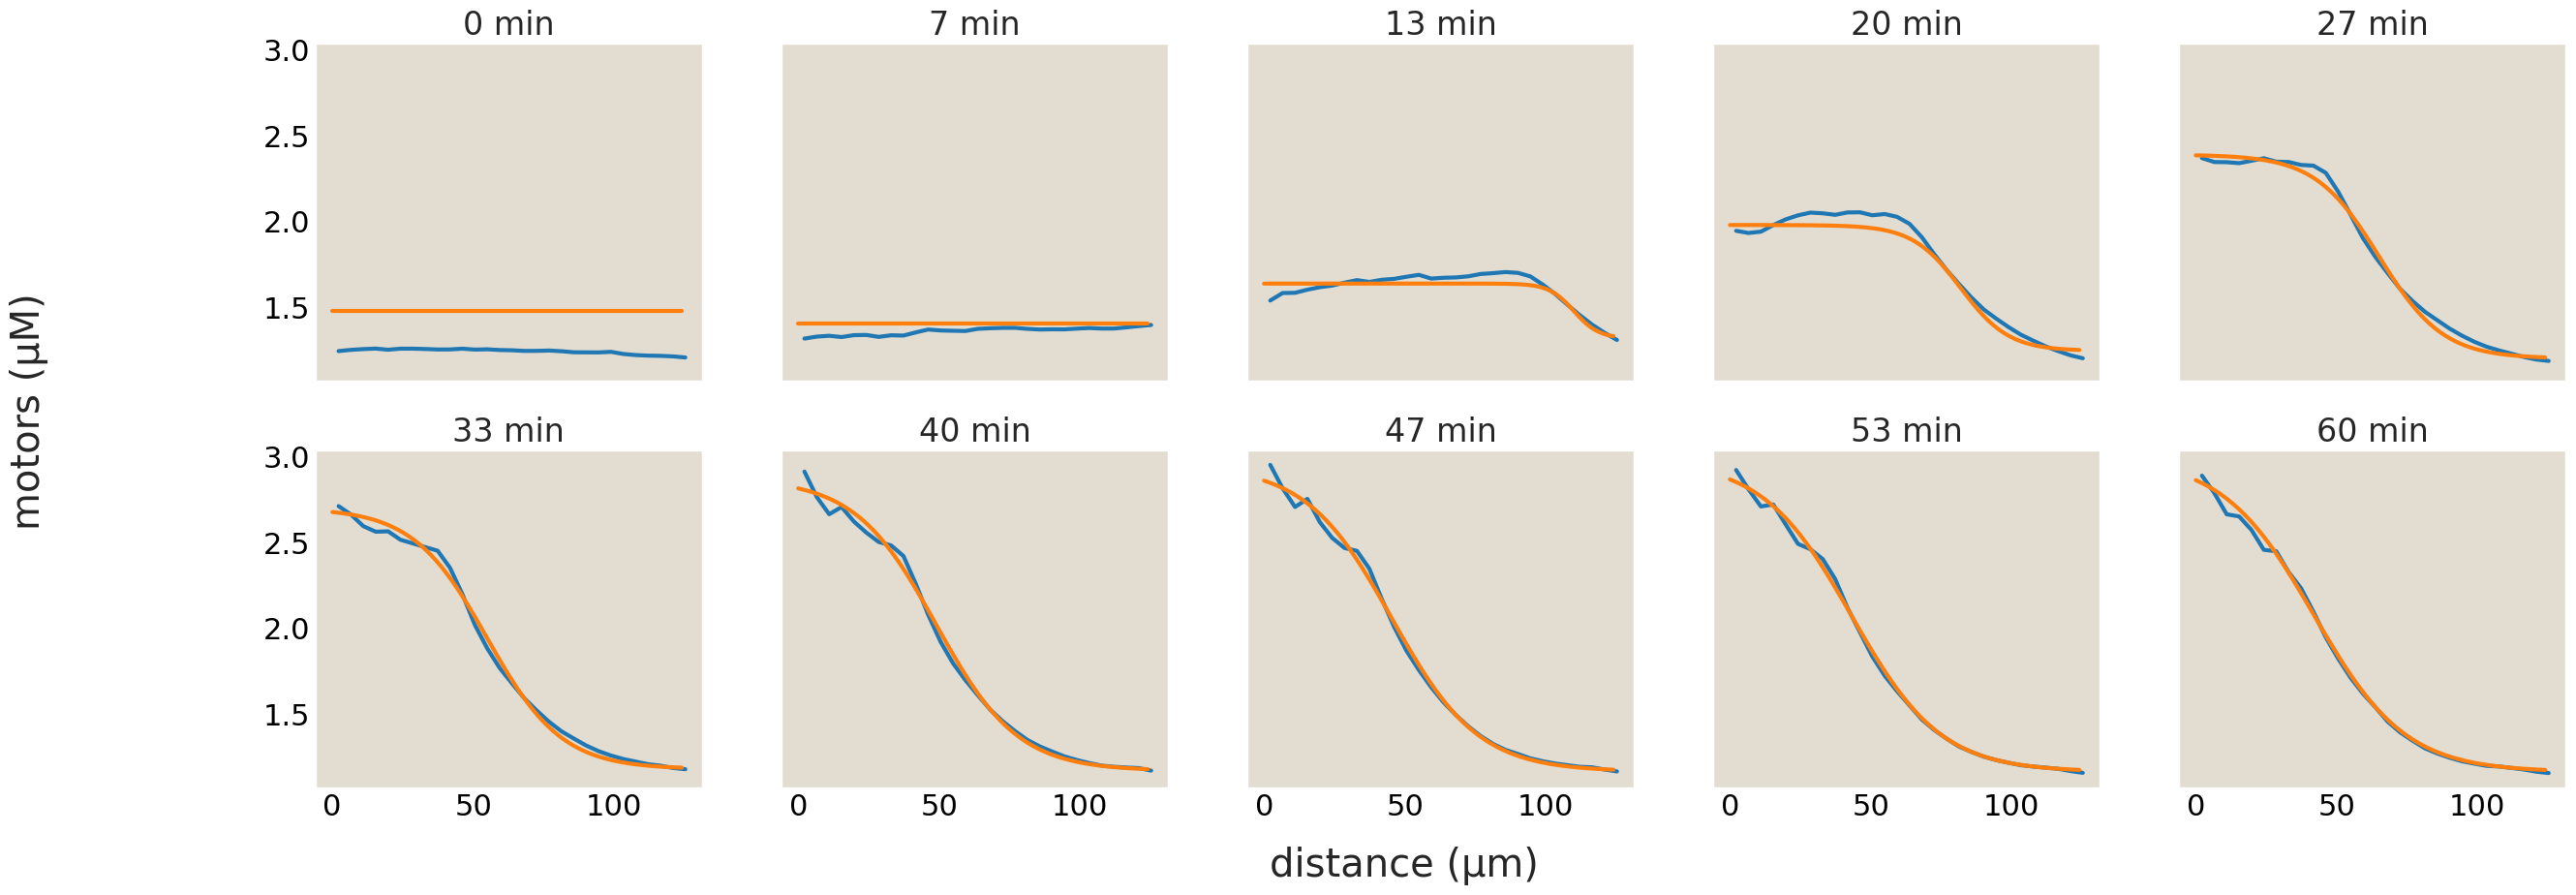

In [142]:
#a=sigmoid(timesMot, -1, 1290, 425, 0.92) #for dimer
a=sigmoid(timesMot, -2, 1290, 425, 1.84)
b=exponential(timesMot, 195, 780, 40)
c = exponential(timesMot, -28, 1000, 17)
#d = sigmoid(timesMot, 0.2, 600, 450, 0.58) #for dimer
d=sigmoid(timesMot, 0.4, 600, 450, 1.16)

fig, ax = plt.subplots(2, 5, figsize=(30,10), sharex=True, sharey=True)
for ii, i in enumerate(np.arange(0, len(all_rMotbins_um), len(all_rMotbins_um)//10)):#len(all_rMTavgs)):
    ax[ii//5][ii%5].plot(all_rMotbins_um[i], all_rMotavgs_mono[i])
    fitcurveplot = sigmoid(np.arange(int(all_rMotbins_um.max())), a[i], b[i], c[i], d[i])
    ax[ii//5][ii%5].plot(np.arange(int(all_rMotbins_um.max())), fitcurveplot)
    ax[ii//5][ii%5].set_title(rf'{round(timesMot[i]/60)} min')
    #plt.scatter(all_rMTbins[i][MTmaxloc[i]], MTmax[i], c='k', s=10)
    #ax.set_title(np.sum((all_rMTavgs[i] - fitcurveplot)**2))
#ax[0][0].set_ylim(0.55, 1.55)

fig.supylabel('motors (µM)')
fig.supxlabel('distance (µm)')

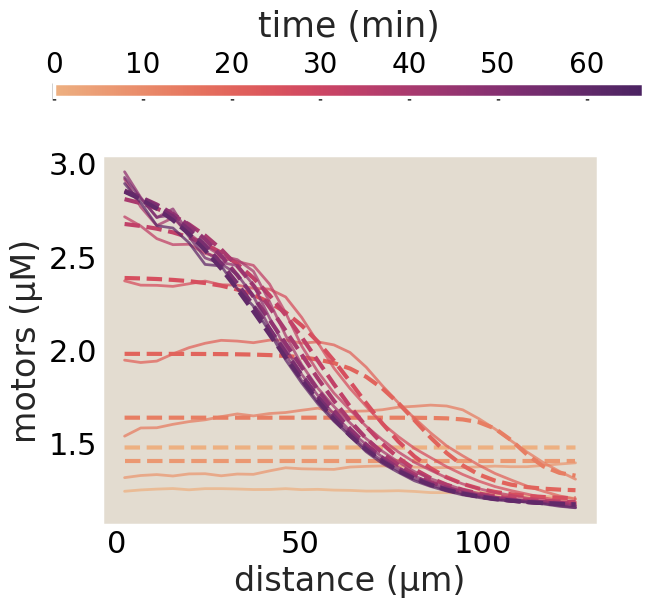

In [143]:
fig, ax = plt.subplots()

#a=sigmoid(timesMot, -1, 1290, 425, 0.92) #for dimer
a=sigmoid(timesMot, -2, 1290, 425, 1.84)
b=exponential(timesMot, 195, 780, 40)
c = exponential(timesMot, -28, 1000, 17)
#d = sigmoid(timesMot, 0.2, 600, 450, 0.58) #for dimer
d=sigmoid(timesMot, 0.4, 600, 450, 1.16)

for time in range(all_rMotavgs_mono.shape[0]):
    if time%20==0:
        plt.plot(all_rMotbins_um[time,:], 
                 all_rMotavgs_mono[time,:], 
                 alpha=0.75, 
                 color=global_time(timesMot[time]), 
                 lw=2)
        plt.plot(all_rMotbins_um[time,:], 
                 sigmoid(all_rMotbins_um[time,:], 
                          a[time], b[time], c[time], d[time]), 
                 ls='--', color=global_time(timesMot[time]))
plt.ylabel('motors (µM)')
plt.xlabel('distance (µm)')
#plt.ylim(0,20)
# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(timesMot)/60, 
                                                                 vmax=max(timesMot)/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)


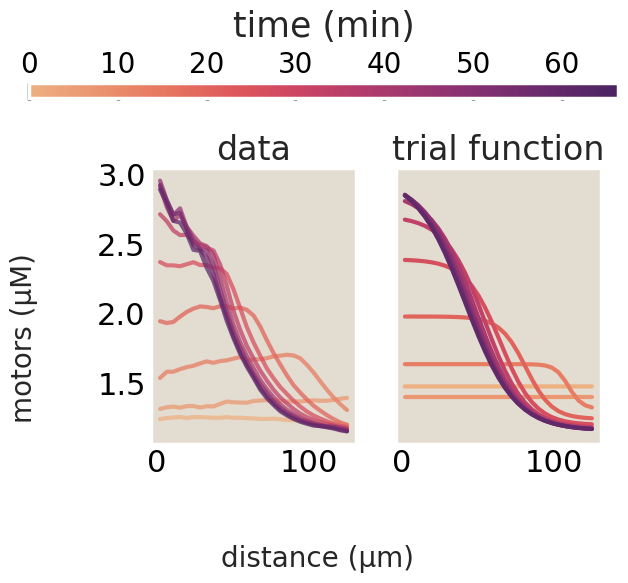

In [144]:
fig, ax = plt.subplots(1,2, sharex=True, sharey=True)

#a=sigmoid(timesMot, -1, 1290, 425, 0.92) #for dimer
a=sigmoid(timesMot, -2, 1290, 425, 1.84)
b=exponential(timesMot, 195, 780, 40)
c = exponential(timesMot, -28, 1000, 17)
#d = sigmoid(timesMot, 0.2, 600, 450, 0.58) #for dimer
d=sigmoid(timesMot, 0.4, 600, 450, 1.16)

for time in range(all_rMotavgs_mono.shape[0]):
    if time%20==0:
        ax[0].plot(all_rMotbins_um[time,:], 
                 all_rMotavgs_mono[time,:], 
                 alpha=0.75, 
                 color=global_time(timesMot[time]))
        ax[1].plot(all_rMotbins_um[time,:], 
                 sigmoid(all_rMotbins_um[time,:], 
                          a[time], b[time], c[time], d[time]), 
                 ls='-', color=global_time(timesMot[time]))
ax[0].set_title('data')
ax[1].set_title('trial function')
fig.supylabel('motors (µM)', fontsize=20)
fig.supxlabel('distance (µm)', fontsize=20)
fig.tight_layout()
#plt.ylim(0,20)
# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.03])  # horizontal [left, bottom, width, height]
#cax = fig.add_axes([1, 0.05, 0.03, 0.91])  # vertical [left, bottom, width, height]

# Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(comsol_time_ls)/60, 
#                                                                  vmax=max(comsol_time_ls)/60)),
#                     cax=cax, orientation='vertical')

# Create an axis for the colorbar that spans all columns
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=min(timesMot)/60, 
                                                                 vmax=max(timesMot)/60)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time (min)', fontsize=25, labelpad=10)
